Bootstrap Random Forest Ensemble for Uncertainty Quantification

Bootstrap Random Forest Ensemble
Samples          : 500
Target           : Hv
Features         : ['Al', 'Co', 'Cr', 'Cu', 'Fe', 'Ni']
Bootstrap models : 50

Optimizing RF Hyperparameters
Fitting 5 folds for each of 40 candidates, totalling 200 fits

Best Hyperparameters:
n_estimators        : 600
min_samples_split   : 8
min_samples_leaf    : 2
max_features        : 1.0
max_depth           : 15
bootstrap           : True

Best CV RMSE : 64.845 Hv

Training Bootstrap Ensemble
Model 01/50 | Unique train samples  309 | OOB samples  191
Model 02/50 | Unique train samples  315 | OOB samples  185
Model 03/50 | Unique train samples  324 | OOB samples  176
Model 04/50 | Unique train samples  316 | OOB samples  184
Model 05/50 | Unique train samples  318 | OOB samples  182
Model 06/50 | Unique train samples  313 | OOB samples  187
Model 07/50 | Unique train samples  318 | OOB samples  182
Model 08/50 | Unique train samples  319 | OOB samples  181
Model 09/50 | Unique train samples  328 | OOB sam

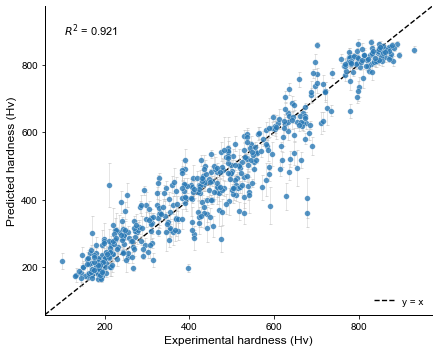


Bootstrap Ensemble Completed
Bootstrap models : 50
OOB R2           : 0.9208
OOB RMSE         : 62.177 Hv
OOB MAE          : 46.514 Hv
Training time    : 88.9 s

Generated Files:
1. Bootstrap_RF_Ensemble.joblib
2. Bootstrap_OOB_Predictions.csv
3. Bootstrap_OOB_Parity_Plot.png


In [1]:
# Workflow:
# 1. Optimize RF hyperparameters once.
# 2. Fix the optimized hyperparameters.
# 3. Generate 50 bootstrap datasets.
# 4. Train 50 RF models using the same hyperparameters.
# 5. Use out-of-bag (OOB) samples for internal validation.
# 6. Aggregate repeated OOB predictions:
#       - Mean prediction
#       - Prediction standard deviation
#
# The prediction standard deviation is used as an estimate
# of model uncertainty.
# ============================================================

from pathlib import Path
from time import perf_counter

import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.ensemble import RandomForestRegressor
from sklearn.model_selection import RandomizedSearchCV, KFold
from sklearn.metrics import (
    r2_score,
    mean_squared_error,
    mean_absolute_error,
)


# ============================================================
# 1. Settings
# ============================================================

RANDOM_STATE = 42

N_BOOTSTRAP = 50

N_ITER = 40
CV_FOLDS = 5


try:
    BASE_DIR = Path(__file__).resolve().parent
except NameError:
    BASE_DIR = Path.cwd()


# Input
DATA_FILE = BASE_DIR / "Data.xlsx"

# Outputs
ENSEMBLE_FILE = BASE_DIR / "Bootstrap_RF_Ensemble.joblib"
OOB_FILE = BASE_DIR / "Bootstrap_OOB_Predictions.csv"
FIGURE_FILE = BASE_DIR / "Bootstrap_OOB_Parity_Plot.png"


# ============================================================
# 2. Load data
# ============================================================

data = (
    pd.read_excel(DATA_FILE)
    .reset_index(drop=True)
)


if data.isnull().sum().sum() > 0:
    raise ValueError(
        "Missing values detected in the input dataset."
    )


target_name = data.columns[0]
feature_names = list(data.columns[1:])


X = data[
    feature_names
].copy()

y = data[
    target_name
].copy()


n_samples = len(data)


print("=" * 65)
print("Bootstrap Random Forest Ensemble")
print("=" * 65)

print(
    f"Samples          : "
    f"{n_samples:,}"
)

print(
    f"Target           : "
    f"{target_name}"
)

print(
    f"Features         : "
    f"{feature_names}"
)

print(
    f"Bootstrap models : "
    f"{N_BOOTSTRAP}"
)


# ============================================================
# 3. RF hyperparameter search space
# ============================================================

param_distributions = {

    "n_estimators": [
        200,
        300,
        400,
        500,
        600,
        800,
        1000,
    ],

    "max_depth": [
        None,
        5,
        10,
        15,
        20,
        30,
        40,
    ],

    "min_samples_split": [
        2,
        4,
        6,
        8,
        10,
    ],

    "min_samples_leaf": [
        1,
        2,
        3,
        4,
        5,
    ],

    "max_features": [
        "sqrt",
        "log2",
        0.5,
        0.7,
        1.0,
    ],

    "bootstrap": [
        True,
        False,
    ],
}


# ============================================================
# 4. Optimize hyperparameters once
# ============================================================

print("\n" + "=" * 65)
print("Optimizing RF Hyperparameters")
print("=" * 65)


base_model = RandomForestRegressor(
    random_state=RANDOM_STATE,
    n_jobs=-1,
)


cv = KFold(
    n_splits=CV_FOLDS,
    shuffle=True,
    random_state=RANDOM_STATE,
)


random_search = RandomizedSearchCV(
    estimator=base_model,
    param_distributions=param_distributions,
    n_iter=N_ITER,
    scoring="neg_mean_squared_error",
    cv=cv,
    n_jobs=-1,
    random_state=RANDOM_STATE,
    verbose=1,
    refit=True,
)


random_search.fit(
    X,
    y,
)


best_params = random_search.best_params_

best_cv_rmse = np.sqrt(
    -random_search.best_score_
)


print("\nBest Hyperparameters:")

for parameter, value in best_params.items():

    print(
        f"{parameter:20s}: "
        f"{value}"
    )


print(
    f"\nBest CV RMSE : "
    f"{best_cv_rmse:.3f} Hv"
)


# ============================================================
# 5. Initialize Bootstrap ensemble
# ============================================================

rng = np.random.default_rng(
    RANDOM_STATE
)


bootstrap_models = []


# Each entry stores all OOB predictions for one original sample
oob_predictions = [
    []
    for _ in range(n_samples)
]


start_time = perf_counter()


# ============================================================
# 6. Train Bootstrap RF ensemble
# ============================================================

print("\n" + "=" * 65)
print("Training Bootstrap Ensemble")
print("=" * 65)


all_indices = np.arange(
    n_samples
)


for bootstrap_index in range(
    N_BOOTSTRAP
):

    model_number = (
        bootstrap_index
        + 1
    )


    # --------------------------------------------------------
    # Bootstrap sampling
    # --------------------------------------------------------

    bootstrap_indices = rng.choice(
        n_samples,
        size=n_samples,
        replace=True,
    )


    inbag_unique = np.unique(
        bootstrap_indices
    )


    oob_indices = np.setdiff1d(
        all_indices,
        inbag_unique,
    )


    # --------------------------------------------------------
    # Bootstrap training data
    # --------------------------------------------------------

    X_bootstrap = X.iloc[
        bootstrap_indices
    ]

    y_bootstrap = y.iloc[
        bootstrap_indices
    ]


    # --------------------------------------------------------
    # Train RF using fixed optimized hyperparameters
    # --------------------------------------------------------

    model = RandomForestRegressor(
        **best_params,
        random_state=(
            RANDOM_STATE
            + model_number
        ),
        n_jobs=-1,
    )


    model.fit(
        X_bootstrap,
        y_bootstrap,
    )


    bootstrap_models.append(
        model
    )


    # --------------------------------------------------------
    # OOB prediction
    # --------------------------------------------------------

    if len(oob_indices) > 0:

        X_oob = X.iloc[
            oob_indices
        ]


        oob_prediction = model.predict(
            X_oob
        )


        for sample_index, prediction in zip(
            oob_indices,
            oob_prediction,
        ):

            oob_predictions[
                sample_index
            ].append(
                float(prediction)
            )


    print(
        f"Model "
        f"{model_number:02d}/{N_BOOTSTRAP} | "
        f"Unique train samples "
        f"{len(inbag_unique):4d} | "
        f"OOB samples "
        f"{len(oob_indices):4d}"
    )


# ============================================================
# 7. Aggregate repeated OOB predictions
# ============================================================

oob_mean = np.full(
    n_samples,
    np.nan,
)

oob_std = np.full(
    n_samples,
    np.nan,
)

oob_count = np.zeros(
    n_samples,
    dtype=int,
)


for sample_index in range(
    n_samples
):

    predictions = np.asarray(
        oob_predictions[
            sample_index
        ],
        dtype=float,
    )


    oob_count[
        sample_index
    ] = len(
        predictions
    )


    if len(predictions) > 0:

        oob_mean[
            sample_index
        ] = np.mean(
            predictions
        )


    if len(predictions) > 1:

        oob_std[
            sample_index
        ] = np.std(
            predictions,
            ddof=1,
        )

    elif len(predictions) == 1:

        oob_std[
            sample_index
        ] = 0.0


# ============================================================
# 8. Create OOB result table
# ============================================================

oob_results = data[
    feature_names
].copy()


oob_results.insert(
    0,
    "Sample_ID",
    np.arange(
        1,
        n_samples + 1,
    ),
)


oob_results[
    "Experimental_Hv"
] = y.to_numpy()


oob_results[
    "Predicted_Hv_Mean"
] = oob_mean


oob_results[
    "Predicted_Hv_STD"
] = oob_std


oob_results[
    "N_OOB_Predictions"
] = oob_count


# ============================================================
# 9. Ensemble OOB performance
# ============================================================

valid_mask = (
    oob_count > 0
)


experimental_hv = (
    y.to_numpy()[
        valid_mask
    ]
)

predicted_mean = (
    oob_mean[
        valid_mask
    ]
)

predicted_std = (
    oob_std[
        valid_mask
    ]
)


ensemble_r2 = r2_score(
    experimental_hv,
    predicted_mean,
)


ensemble_rmse = np.sqrt(
    mean_squared_error(
        experimental_hv,
        predicted_mean,
    )
)


ensemble_mae = mean_absolute_error(
    experimental_hv,
    predicted_mean,
)


print("\n" + "=" * 65)
print("Bootstrap Ensemble OOB Performance")
print("=" * 65)


print(
    f"R2   : "
    f"{ensemble_r2:.4f}"
)

print(
    f"RMSE : "
    f"{ensemble_rmse:.3f} Hv"
)

print(
    f"MAE  : "
    f"{ensemble_mae:.3f} Hv"
)


print(
    f"\nMean OOB predictions/sample : "
    f"{oob_count[valid_mask].mean():.2f}"
)

print(
    f"Minimum                      : "
    f"{oob_count[valid_mask].min()}"
)

print(
    f"Maximum                      : "
    f"{oob_count[valid_mask].max()}"
)


# ============================================================
# 10. Save OOB predictions
# ============================================================

oob_results.to_csv(
    OOB_FILE,
    index=False,
)


# ============================================================
# 11. Save Bootstrap ensemble
# ============================================================

ensemble_package = {

    "models": bootstrap_models,

    "features": feature_names,

    "target": target_name,

    "best_params": best_params,

    "cv_rmse": best_cv_rmse,

    "n_bootstrap": N_BOOTSTRAP,

    "random_state": RANDOM_STATE,
}


joblib.dump(
    ensemble_package,
    ENSEMBLE_FILE,
    compress=3,
)


# ============================================================
# 12. OOB parity plot
# ============================================================

plt.rcParams.update({
    "font.family": "Arial",
    "font.size": 10,
    "axes.labelsize": 12,
    "axes.linewidth": 1.0,
    "xtick.labelsize": 10,
    "ytick.labelsize": 10,
    "xtick.direction": "out",
    "ytick.direction": "out",
})


fig, ax = plt.subplots(
    figsize=(6.2, 5.0)
)


# ------------------------------------------------------------
# Prediction uncertainty
# ------------------------------------------------------------

ax.errorbar(
    experimental_hv,
    predicted_mean,
    yerr=predicted_std,
    fmt="none",
    ecolor="#BDBDBD",
    elinewidth=0.7,
    capsize=1.5,
    alpha=0.55,
    zorder=1,
)


# ------------------------------------------------------------
# Mean OOB predictions
# ------------------------------------------------------------

ax.scatter(
    experimental_hv,
    predicted_mean,
    s=32,
    color="#2878B5",
    alpha=0.80,
    edgecolors="white",
    linewidth=0.35,
    zorder=2,
)


# ------------------------------------------------------------
# Axis limits
# ------------------------------------------------------------

lower_error = (
    predicted_mean
    - predicted_std
)

upper_error = (
    predicted_mean
    + predicted_std
)


plot_min = min(
    experimental_hv.min(),
    lower_error.min(),
)

plot_max = max(
    experimental_hv.max(),
    upper_error.max(),
)


plot_range = (
    plot_max
    - plot_min
)

padding = (
    plot_range
    * 0.05
)


plot_min -= padding
plot_max += padding


# ------------------------------------------------------------
# y = x
# ------------------------------------------------------------

ax.plot(
    [
        plot_min,
        plot_max,
    ],
    [
        plot_min,
        plot_max,
    ],
    linestyle="--",
    linewidth=1.4,
    color="black",
    label="y = x",
    zorder=0,
)


ax.set_xlim(
    plot_min,
    plot_max,
)

ax.set_ylim(
    plot_min,
    plot_max,
)


ax.set_xlabel(
    "Experimental hardness (Hv)"
)

ax.set_ylabel(
    "Predicted hardness (Hv)"
)


ax.text(
    0.05,
    0.95,
    f"$R^2$ = {ensemble_r2:.3f}",
    transform=ax.transAxes,
    fontsize=11,
    verticalalignment="top",
)


ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)


ax.tick_params(
    axis="both",
    direction="out",
)


ax.legend(
    loc="lower right",
    frameon=False,
)


ax.grid(False)


plt.tight_layout()


plt.savefig(
    FIGURE_FILE,
    dpi=600,
    bbox_inches="tight",
    facecolor="white",
)


plt.show()


# ============================================================
# 13. Summary
# ============================================================

elapsed_time = (
    perf_counter()
    - start_time
)


print("\n" + "=" * 65)
print("Bootstrap Ensemble Completed")
print("=" * 65)


print(
    f"Bootstrap models : "
    f"{len(bootstrap_models)}"
)

print(
    f"OOB R2           : "
    f"{ensemble_r2:.4f}"
)

print(
    f"OOB RMSE         : "
    f"{ensemble_rmse:.3f} Hv"
)

print(
    f"OOB MAE          : "
    f"{ensemble_mae:.3f} Hv"
)

print(
    f"Training time    : "
    f"{elapsed_time:.1f} s"
)


print("\nGenerated Files:")

print(
    f"1. {ENSEMBLE_FILE.name}"
)

print(
    f"2. {OOB_FILE.name}"
)

print(
    f"3. {FIGURE_FILE.name}"
)

Alloy Composition Design Space Generation

In [2]:
from pathlib import Path

import pandas as pd


# ============================================================
# 1. Settings
# ============================================================

STEP = 1          # Composition resolution (at.%)
CHUNK_SIZE = 100_000

try:
    BASE_DIR = Path(__file__).resolve().parent
except NameError:
    BASE_DIR = Path.cwd()


OUTPUT_FILE = BASE_DIR / "Design_Space.csv"


# ============================================================
# 2. Composition ranges
# ============================================================
#
# Constraints:
#
# 15 < Al < 47
# 5  < Co < 22
# 6  < Cr < 34
# 5  < Cu < 16
# 5  < Fe < 31
# 5  < Ni < 22
#
# With STEP = 1 at.%:
#
# Al = 16–46
# Co = 6–21
# Cr = 7–33
# Cu = 6–15
# Fe = 6–30
# Ni = 6–21
#
# Additional constraint:
#
# Al + Co + Cr + Cu + Fe + Ni = 100 at.%
#
# ============================================================

al_range = range(16, 47, STEP)
co_range = range(6, 22, STEP)
cr_range = range(7, 34, STEP)
cu_range = range(6, 16, STEP)
fe_range = range(6, 31, STEP)

ni_min = 6
ni_max = 21

columns = [
    "Al",
    "Co",
    "Cr",
    "Cu",
    "Fe",
    "Ni",
]


# ============================================================
# 3. Generate design space
# ============================================================

print("=" * 60)
print("Generating Alloy Design Space")
print("=" * 60)


buffer = []

total_candidates = 0
first_write = True


for al in al_range:

    for co in co_range:

        for cr in cr_range:

            for cu in cu_range:

                for fe in fe_range:

                    # Ni is determined by the 100 at.% constraint
                    ni = 100 - (
                        al
                        + co
                        + cr
                        + cu
                        + fe
                    )

                    # Keep only candidates satisfying the Ni range
                    if ni_min <= ni <= ni_max:

                        buffer.append([
                            al,
                            co,
                            cr,
                            cu,
                            fe,
                            ni,
                        ])

                        total_candidates += 1


                    # ------------------------------------------------
                    # Write candidates in chunks to limit memory usage
                    # ------------------------------------------------

                    if len(buffer) >= CHUNK_SIZE:

                        chunk = pd.DataFrame(
                            buffer,
                            columns=columns,
                        )

                        chunk.to_csv(
                            OUTPUT_FILE,
                            mode="w" if first_write else "a",
                            header=first_write,
                            index=False,
                        )

                        first_write = False
                        buffer.clear()

                        print(
                            f"{total_candidates:,} "
                            f"candidates generated"
                        )


# ============================================================
# 4. Save remaining candidates
# ============================================================

if buffer:

    chunk = pd.DataFrame(
        buffer,
        columns=columns,
    )

    chunk.to_csv(
        OUTPUT_FILE,
        mode="w" if first_write else "a",
        header=first_write,
        index=False,
    )


# ============================================================
# 5. Summary
# ============================================================

print("\n" + "=" * 60)
print("Design Space Generation Completed")
print("=" * 60)

print(
    f"Total candidates : "
    f"{total_candidates:,}"
)

print(
    f"Step size        : "
    f"{STEP} at.%"
)

print(
    f"Output file      : "
    f"{OUTPUT_FILE.name}"
)

Generating Alloy Design Space
100,000 candidates generated
200,000 candidates generated
300,000 candidates generated
400,000 candidates generated
500,000 candidates generated
600,000 candidates generated
700,000 candidates generated
800,000 candidates generated
900,000 candidates generated
1,000,000 candidates generated
1,100,000 candidates generated
1,200,000 candidates generated

Design Space Generation Completed
Total candidates : 1,224,117
Step size        : 1 at.%
Output file      : Design_Space.csv


Bootstrap RF Ensemble Prediction for Alloy Design Space

In [3]:
# For each candidate composition:
#
# 1. Predict hardness using all Bootstrap RF models.
# 2. Calculate the ensemble mean prediction.
# 3. Calculate the prediction standard deviation.
#
# Outputs:
# Mean_Predicted_Hv -> predicted performance
# Prediction_STD    -> predictive uncertainty
#
# Candidate selection is performed in the next step.
# ============================================================

from pathlib import Path
from time import perf_counter

import joblib
import numpy as np
import pandas as pd


# ============================================================
# 1. Settings
# ============================================================

CHUNK_SIZE = 50_000


try:
    BASE_DIR = Path(__file__).resolve().parent
except NameError:
    BASE_DIR = Path.cwd()


# Input files
ENSEMBLE_FILE = BASE_DIR / "Bootstrap_RF_Ensemble.joblib"
DESIGN_SPACE_FILE = BASE_DIR / "Design_Space.csv"

# Output file
PREDICTION_FILE = BASE_DIR / "Ensemble_DesignSpace_Predictions.csv"


# ============================================================
# 2. Load Bootstrap RF ensemble
# ============================================================

ensemble_package = joblib.load(
    ENSEMBLE_FILE
)


models = ensemble_package["models"]
feature_names = ensemble_package["features"]
target_name = ensemble_package["target"]


print("=" * 65)
print("Bootstrap Ensemble Design-Space Prediction")
print("=" * 65)

print(
    f"Number of models : "
    f"{len(models)}"
)

print(
    f"Target           : "
    f"{target_name}"
)

print(
    f"Features         : "
    f"{feature_names}"
)


# ============================================================
# 3. Validate design space
# ============================================================

design_head = pd.read_csv(
    DESIGN_SPACE_FILE,
    nrows=5,
)


missing_features = [
    feature
    for feature in feature_names
    if feature not in design_head.columns
]


if missing_features:

    raise ValueError(
        f"Missing features in design space: "
        f"{missing_features}"
    )


print(
    "\nDesign-space features validated."
)


# ============================================================
# 4. Remove previous output
# ============================================================

if PREDICTION_FILE.exists():

    PREDICTION_FILE.unlink()


# ============================================================
# 5. Predict entire design space
# ============================================================

print("\n" + "=" * 65)
print("Predicting Entire Design Space")
print("=" * 65)


start_time = perf_counter()

first_chunk = True
total_processed = 0
chunk_number = 0


for chunk in pd.read_csv(
    DESIGN_SPACE_FILE,
    chunksize=CHUNK_SIZE,
):

    chunk_number += 1


    # --------------------------------------------------------
    # RF input
    # --------------------------------------------------------

    X_candidate = chunk[
        feature_names
    ]


    # --------------------------------------------------------
    # Predictions from all Bootstrap RF models
    #
    # Shape:
    # n_models × n_candidates
    # --------------------------------------------------------

    all_predictions = np.asarray([
        model.predict(
            X_candidate
        )
        for model in models
    ])


    # --------------------------------------------------------
    # Ensemble mean prediction
    # --------------------------------------------------------

    mean_prediction = np.mean(
        all_predictions,
        axis=0,
    )


    # --------------------------------------------------------
    # Ensemble prediction uncertainty
    # --------------------------------------------------------

    prediction_std = np.std(
        all_predictions,
        axis=0,
        ddof=1,
    )


    # --------------------------------------------------------
    # Add prediction results
    # --------------------------------------------------------

    chunk[
        "Mean_Predicted_Hv"
    ] = mean_prediction


    chunk[
        "Prediction_STD"
    ] = prediction_std


    # --------------------------------------------------------
    # Arrange output columns
    # --------------------------------------------------------

    output_columns = (
        feature_names
        + [
            "Mean_Predicted_Hv",
            "Prediction_STD",
        ]
    )


    chunk = chunk[
        output_columns
    ]


    # --------------------------------------------------------
    # Save current chunk
    # --------------------------------------------------------

    chunk.to_csv(
        PREDICTION_FILE,
        mode=(
            "w"
            if first_chunk
            else "a"
        ),
        header=first_chunk,
        index=False,
    )


    first_chunk = False


    # --------------------------------------------------------
    # Progress
    # --------------------------------------------------------

    total_processed += len(
        chunk
    )


    elapsed_time = (
        perf_counter()
        - start_time
    )


    print(
        f"Chunk "
        f"{chunk_number:3d} | "
        f"Processed "
        f"{total_processed:,} | "
        f"Mean Hv max "
        f"{mean_prediction.max():.2f} | "
        f"STD max "
        f"{prediction_std.max():.2f} | "
        f"Time "
        f"{elapsed_time:.1f} s"
    )


# ============================================================
# 6. Final summary
# ============================================================

elapsed_time = (
    perf_counter()
    - start_time
)


print("\n" + "=" * 65)
print("Ensemble Prediction Completed")
print("=" * 65)


print(
    f"Candidates predicted : "
    f"{total_processed:,}"
)

print(
    f"Bootstrap models     : "
    f"{len(models)}"
)

print(
    f"Calculation time     : "
    f"{elapsed_time:.1f} s"
)


print("\nGenerated File:")

print(
    PREDICTION_FILE.name
)

Bootstrap Ensemble Design-Space Prediction
Number of models : 50
Target           : Hv
Features         : ['Al', 'Co', 'Cr', 'Cu', 'Fe', 'Ni']

Design-space features validated.

Predicting Entire Design Space
Chunk   1 | Processed 50,000 | Mean Hv max 568.57 | STD max 40.73 | Time 16.4 s
Chunk   2 | Processed 100,000 | Mean Hv max 572.77 | STD max 41.89 | Time 31.4 s
Chunk   3 | Processed 150,000 | Mean Hv max 574.98 | STD max 41.09 | Time 46.8 s
Chunk   4 | Processed 200,000 | Mean Hv max 577.24 | STD max 40.57 | Time 60.4 s
Chunk   5 | Processed 250,000 | Mean Hv max 581.73 | STD max 40.13 | Time 75.2 s
Chunk   6 | Processed 300,000 | Mean Hv max 597.55 | STD max 40.56 | Time 90.9 s
Chunk   7 | Processed 350,000 | Mean Hv max 631.18 | STD max 42.33 | Time 106.9 s
Chunk   8 | Processed 400,000 | Mean Hv max 638.59 | STD max 40.99 | Time 121.8 s
Chunk   9 | Processed 450,000 | Mean Hv max 641.82 | STD max 35.55 | Time 138.1 s
Chunk  10 | Processed 500,000 | Mean Hv max 649.23 | STD max

UMAP Visualization of Ensemble-Predicted Design Space

In [ ]:
# UMAP input:
# Al, Co, Cr, Cu, Fe, Ni
#
# Color mapping:
# 1. Mean predicted hardness
# 2. Prediction uncertainty (STD)
#
# UMAP is fitted on a representative subset,
# while the entire design space is transformed and plotted.
# ============================================================

from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.preprocessing import StandardScaler
import umap.umap_ as umap


# ============================================================
# 1. Settings
# ============================================================

RANDOM_STATE = 42

# Number of samples used to fit UMAP
UMAP_TRAIN_SIZE = 50_000

# Number of samples transformed per batch
TRANSFORM_CHUNK_SIZE = 100_000


FEATURES = [
    "Al",
    "Co",
    "Cr",
    "Cu",
    "Fe",
    "Ni",
]


MEAN_COLUMN = "Mean_Predicted_Hv"
STD_COLUMN = "Prediction_STD"


try:
    BASE_DIR = Path(__file__).resolve().parent
except NameError:
    BASE_DIR = Path.cwd()


# Input
DATA_FILE = BASE_DIR / "Ensemble_DesignSpace_Predictions.csv"

# Outputs
MEAN_FIGURE = BASE_DIR / "Ensemble_UMAP_Mean_Hardness.png"
STD_FIGURE = BASE_DIR / "Ensemble_UMAP_Uncertainty.png"


# ============================================================
# 2. Load ensemble predictions
# ============================================================

data = pd.read_csv(
    DATA_FILE
)


required_columns = (
    FEATURES
    + [
        MEAN_COLUMN,
        STD_COLUMN,
    ]
)


missing_columns = [
    column
    for column in required_columns
    if column not in data.columns
]


if missing_columns:

    raise ValueError(
        f"Missing required columns: "
        f"{missing_columns}"
    )


print("=" * 65)
print("UMAP Visualization of Predicted Design Space")
print("=" * 65)

print(
    f"Candidates : "
    f"{len(data):,}"
)

print(
    f"Features   : "
    f"{FEATURES}"
)


# ============================================================
# 3. Prepare composition matrix
# ============================================================

X = data[
    FEATURES
].to_numpy(
    dtype=float
)


# ============================================================
# 4. Standardize composition features
# ============================================================

print(
    "\nStandardizing composition features..."
)


scaler = StandardScaler()


X_scaled = scaler.fit_transform(
    X
)


# ============================================================
# 5. Select representative subset for UMAP fitting
# ============================================================

rng = np.random.default_rng(
    RANDOM_STATE
)


if len(data) > UMAP_TRAIN_SIZE:

    training_indices = rng.choice(
        len(data),
        size=UMAP_TRAIN_SIZE,
        replace=False,
    )

else:

    training_indices = np.arange(
        len(data)
    )


X_umap_train = X_scaled[
    training_indices
]


print(
    f"Samples used to fit UMAP : "
    f"{len(X_umap_train):,}"
)


# ============================================================
# 6. Build and fit UMAP
# ============================================================

umap_model = umap.UMAP(
    n_components=2,
    n_neighbors=30,
    min_dist=0.10,
    metric="euclidean",
    random_state=RANDOM_STATE,
    low_memory=True,
)


print("\n" + "=" * 65)
print("Fitting UMAP")
print("=" * 65)


umap_model.fit(
    X_umap_train
)


# ============================================================
# 7. Transform entire design space
# ============================================================

print("\n" + "=" * 65)
print("Transforming Entire Design Space")
print("=" * 65)


umap_coordinates = np.zeros(
    (
        len(data),
        2,
    ),
    dtype=np.float32,
)


for start in range(
    0,
    len(data),
    TRANSFORM_CHUNK_SIZE,
):

    end = min(
        start + TRANSFORM_CHUNK_SIZE,
        len(data),
    )


    umap_coordinates[
        start:end
    ] = umap_model.transform(
        X_scaled[
            start:end
        ]
    )


    print(
        f"Transformed : "
        f"{end:,} / {len(data):,}"
    )


umap_1 = umap_coordinates[:, 0]
umap_2 = umap_coordinates[:, 1]


# ============================================================
# 8. Common UMAP limits
# ============================================================

x_min = umap_1.min()
x_max = umap_1.max()

y_min = umap_2.min()
y_max = umap_2.max()


x_padding = (
    x_max - x_min
) * 0.03

y_padding = (
    y_max - y_min
) * 0.03


x_limits = (
    x_min - x_padding,
    x_max + x_padding,
)

y_limits = (
    y_min - y_padding,
    y_max + y_padding,
)


# ============================================================
# 9. Plot style
# ============================================================

plt.rcParams.update({
    "font.family": "Arial",
    "font.size": 11,
})


# ============================================================
# 10. Helper function for clean UMAP axes
# ============================================================

def format_umap_axis(ax):
    """
    Remove conventional axes and add simple UMAP1/UMAP2 arrows
    in the lower-left corner.
    """

    ax.set_xlim(
        x_limits
    )

    ax.set_ylim(
        y_limits
    )


    # Remove frame and ticks
    for spine in ax.spines.values():

        spine.set_visible(
            False
        )


    ax.set_xticks([])
    ax.set_yticks([])


    # --------------------------------------------------------
    # UMAP axis arrows
    # --------------------------------------------------------

    x0 = 0.07
    y0 = 0.08

    arrow_length_x = 0.16
    arrow_length_y = 0.18


    ax.annotate(
        "",
        xy=(
            x0 + arrow_length_x,
            y0,
        ),
        xytext=(
            x0,
            y0,
        ),
        xycoords="axes fraction",
        arrowprops=dict(
            arrowstyle="-|>",
            linewidth=1.2,
            color="black",
        ),
    )


    ax.annotate(
        "",
        xy=(
            x0,
            y0 + arrow_length_y,
        ),
        xytext=(
            x0,
            y0,
        ),
        xycoords="axes fraction",
        arrowprops=dict(
            arrowstyle="-|>",
            linewidth=1.2,
            color="black",
        ),
    )


    ax.text(
        x0 + arrow_length_x / 2,
        y0 - 0.035,
        "UMAP1",
        transform=ax.transAxes,
        ha="center",
        va="top",
        fontsize=11,
    )


    ax.text(
        x0 - 0.025,
        y0 + arrow_length_y / 2,
        "UMAP2",
        transform=ax.transAxes,
        ha="right",
        va="center",
        rotation=90,
        fontsize=11,
    )


# ============================================================
# 11. Mean predicted hardness
# ============================================================

fig, ax = plt.subplots(
    figsize=(6.3, 5.2)
)


scatter = ax.scatter(
    umap_1,
    umap_2,
    c=data[MEAN_COLUMN],
    cmap="viridis",
    s=1.0,
    alpha=0.65,
    linewidths=0,
)


format_umap_axis(
    ax
)


cbar = fig.colorbar(
    scatter,
    ax=ax,
    pad=0.02,
    fraction=0.045,
)


cbar.set_label(
    "Mean predicted hardness (Hv)",
    fontsize=11,
)


cbar.ax.tick_params(
    labelsize=9,
    length=3,
)


plt.tight_layout()


plt.savefig(
    MEAN_FIGURE,
    dpi=600,
    bbox_inches="tight",
    facecolor="white",
)


plt.show()


# ============================================================
# 12. Prediction uncertainty
# ============================================================

fig, ax = plt.subplots(
    figsize=(6.3, 5.2)
)


scatter = ax.scatter(
    umap_1,
    umap_2,
    c=data[STD_COLUMN],
    cmap="plasma",
    s=1.0,
    alpha=0.65,
    linewidths=0,
)


format_umap_axis(
    ax
)


cbar = fig.colorbar(
    scatter,
    ax=ax,
    pad=0.02,
    fraction=0.045,
)


cbar.set_label(
    "Prediction uncertainty (Hv)",
    fontsize=11,
)


cbar.ax.tick_params(
    labelsize=9,
    length=3,
)


plt.tight_layout()


plt.savefig(
    STD_FIGURE,
    dpi=600,
    bbox_inches="tight",
    facecolor="white",
)


plt.show()


# ============================================================
# 13. Summary
# ============================================================

print("\n" + "=" * 65)
print("UMAP Visualization Completed")
print("=" * 65)


print(
    f"Design-space candidates : "
    f"{len(data):,}"
)

print(
    f"UMAP training samples   : "
    f"{len(X_umap_train):,}"
)


print(
    f"\nMean predicted Hv : "
    f"{data[MEAN_COLUMN].min():.3f} - "
    f"{data[MEAN_COLUMN].max():.3f} Hv"
)


print(
    f"Prediction STD    : "
    f"{data[STD_COLUMN].min():.3f} - "
    f"{data[STD_COLUMN].max():.3f} Hv"
)


print("\nGenerated Figures:")

print(
    f"1. {MEAN_FIGURE.name}"
)

print(
    f"2. {STD_FIGURE.name}"
)

Three sampling strategies + K-means representative sampling

Final Candidate Selection
Design-space candidates : 1,224,117
Candidate pool/strategy : 10,000
K-means clusters        : 10

Balanced Acquisition Function:
0.5 × Normalized Mean + 0.5 × Normalized STD

Mean prediction range : 379.469 – 823.088 Hv
Uncertainty range     : 5.301 – 42.326 Hv

Candidate Pools:
Exploration  : 10,000
Balanced     : 10,000
Exploitation : 10,000


C:\Users\Libin Zhang\anaconda3\envs\pytorch\lib\site-packages\matplotlib\axes\_axes.py:1183: RuntimeWarning: All-NaN axis encountered
  minx = np.nanmin(masked_verts[..., 0])
C:\Users\Libin Zhang\anaconda3\envs\pytorch\lib\site-packages\matplotlib\axes\_axes.py:1184: RuntimeWarning: All-NaN axis encountered
  maxx = np.nanmax(masked_verts[..., 0])
C:\Users\Libin Zhang\anaconda3\envs\pytorch\lib\site-packages\matplotlib\axes\_axes.py:1185: RuntimeWarning: All-NaN axis encountered
  miny = np.nanmin(masked_verts[..., 1])
C:\Users\Libin Zhang\anaconda3\envs\pytorch\lib\site-packages\matplotlib\axes\_axes.py:1186: RuntimeWarning: All-NaN axis encountered
  maxy = np.nanmax(masked_verts[..., 1])


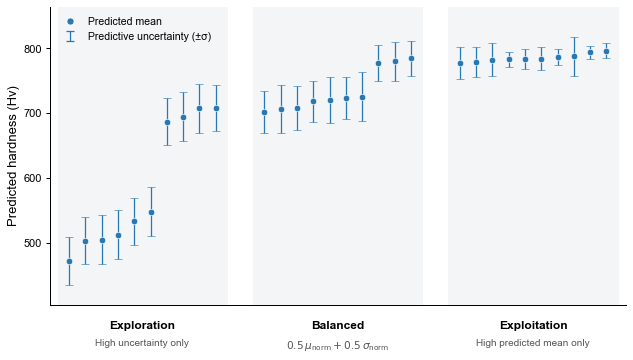


Final Candidate Selection Completed
Candidate pool per strategy : 10,000
K-means clusters            : 10
Selected candidates         : 10 per strategy

Strategies:
Exploration  : Top 10,000 highest-uncertainty candidates
Balanced     : Top 10,000 by 0.5 normalized mean + 0.5 normalized uncertainty
Exploitation : Top 10,000 highest predicted mean

Generated Files:
1. Exploration_Selected_10.xlsx
2. Balanced_Selected_10.xlsx
3. Exploitation_Selected_10.xlsx
4. All_Selected_Candidates.xlsx
5. Sampling_Strategies.png


In [4]:
# ============================================================
# Final Candidate Selection:
# Exploration, Balanced, and Exploitation Strategies
# ============================================================
#
# Workflow:
#
# Entire predicted design space
#           ↓
# Three candidate-selection strategies
#           ↓
# Top 10,000 candidates per strategy
#           ↓
# K-means clustering in composition space (K = 10)
#           ↓
# Select the real candidate nearest to each centroid
#           ↓
# 10 representative candidates per strategy
#
# Strategies:
#
# Exploration:
#   Highest prediction uncertainty
#
# Balanced:
#   0.5 × normalized mean prediction
# + 0.5 × normalized uncertainty
#
# Exploitation:
#   Highest predicted mean hardness
# ============================================================

from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.cluster import KMeans
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import pairwise_distances_argmin_min

from matplotlib.lines import Line2D


# ============================================================
# 1. Settings
# ============================================================

TOP_POOL = 10_000
N_CLUSTERS = 10

# Balanced acquisition weights
ALPHA = 0.5
BETA = 0.5

RANDOM_STATE = 42


FEATURES = [
    "Al",
    "Co",
    "Cr",
    "Cu",
    "Fe",
    "Ni",
]


MEAN_COLUMN = "Mean_Predicted_Hv"
STD_COLUMN = "Prediction_STD"


try:
    BASE_DIR = Path(__file__).resolve().parent
except NameError:
    BASE_DIR = Path.cwd()


# Input
DATA_FILE = BASE_DIR / "Ensemble_DesignSpace_Predictions.csv"

# Outputs
EXPLORATION_FILE = BASE_DIR / "Exploration_Selected_10.xlsx"
BALANCED_FILE = BASE_DIR / "Balanced_Selected_10.xlsx"
EXPLOITATION_FILE = BASE_DIR / "Exploitation_Selected_10.xlsx"

ALL_SELECTED_FILE = BASE_DIR / "All_Selected_Candidates.xlsx"

FIGURE_FILE = BASE_DIR / "Sampling_Strategies.png"


# ============================================================
# 2. Load predicted design space
# ============================================================

data = pd.read_csv(
    DATA_FILE
)


required_columns = (
    FEATURES
    + [
        MEAN_COLUMN,
        STD_COLUMN,
    ]
)


missing_columns = [
    column
    for column in required_columns
    if column not in data.columns
]


if missing_columns:
    raise ValueError(
        f"Missing required columns: "
        f"{missing_columns}"
    )


data = (
    data
    .dropna(
        subset=required_columns
    )
    .reset_index(drop=True)
)


print("=" * 70)
print("Final Candidate Selection")
print("=" * 70)

print(
    f"Design-space candidates : "
    f"{len(data):,}"
)

print(
    f"Candidate pool/strategy : "
    f"{TOP_POOL:,}"
)

print(
    f"K-means clusters        : "
    f"{N_CLUSTERS}"
)


# ============================================================
# 3. Normalize mean prediction and uncertainty
# ============================================================
#
# Min-Max normalization over the ENTIRE design space:
#
# x_norm = (x - xmin) / (xmax - xmin)
#
# ============================================================

mean_min = data[
    MEAN_COLUMN
].min()

mean_max = data[
    MEAN_COLUMN
].max()


std_min = data[
    STD_COLUMN
].min()

std_max = data[
    STD_COLUMN
].max()


if mean_max > mean_min:

    data[
        "Normalized_Mean"
    ] = (
        data[MEAN_COLUMN]
        - mean_min
    ) / (
        mean_max
        - mean_min
    )

else:

    data[
        "Normalized_Mean"
    ] = 0.0


if std_max > std_min:

    data[
        "Normalized_STD"
    ] = (
        data[STD_COLUMN]
        - std_min
    ) / (
        std_max
        - std_min
    )

else:

    data[
        "Normalized_STD"
    ] = 0.0


# ============================================================
# 4. Balanced acquisition score
# ============================================================
#
# Acquisition =
#
# 0.5 × Normalized Mean
# +
# 0.5 × Normalized STD
#
# ============================================================

data[
    "Acquisition_Score"
] = (
    ALPHA
    * data["Normalized_Mean"]
    +
    BETA
    * data["Normalized_STD"]
)


print("\nBalanced Acquisition Function:")

print(
    f"{ALPHA:.1f} × Normalized Mean "
    f"+ {BETA:.1f} × Normalized STD"
)


print(
    f"\nMean prediction range : "
    f"{mean_min:.3f} – {mean_max:.3f} Hv"
)

print(
    f"Uncertainty range     : "
    f"{std_min:.3f} – {std_max:.3f} Hv"
)


# ============================================================
# 5. Select Top-10,000 candidate pools
# ============================================================

# Exploration:
# Highest uncertainty
exploration_pool = (
    data
    .nlargest(
        TOP_POOL,
        STD_COLUMN,
    )
    .copy()
    .reset_index(drop=True)
)


# Balanced:
# Highest acquisition score
balanced_pool = (
    data
    .nlargest(
        TOP_POOL,
        "Acquisition_Score",
    )
    .copy()
    .reset_index(drop=True)
)


# Exploitation:
# Highest predicted mean
exploitation_pool = (
    data
    .nlargest(
        TOP_POOL,
        MEAN_COLUMN,
    )
    .copy()
    .reset_index(drop=True)
)


print("\nCandidate Pools:")

print(
    f"Exploration  : "
    f"{len(exploration_pool):,}"
)

print(
    f"Balanced     : "
    f"{len(balanced_pool):,}"
)

print(
    f"Exploitation : "
    f"{len(exploitation_pool):,}"
)


# ============================================================
# 6. K-means representative-selection function
# ============================================================

def select_representatives(
    candidate_pool,
    strategy_name,
):
    """
    Select representative real alloy candidates.

    Workflow:
    1. Use the six composition variables only.
    2. Standardize composition variables.
    3. Perform K-means clustering (K = 10).
    4. Select the real candidate nearest to each centroid.
    """

    pool = (
        candidate_pool
        .copy()
        .reset_index(drop=True)
    )


    # --------------------------------------------------------
    # Composition matrix
    # --------------------------------------------------------

    X = pool[
        FEATURES
    ].to_numpy(
        dtype=float
    )


    # --------------------------------------------------------
    # Standardize composition variables
    # --------------------------------------------------------

    scaler = StandardScaler()

    X_scaled = scaler.fit_transform(
        X
    )


    # --------------------------------------------------------
    # K-means clustering
    # --------------------------------------------------------

    kmeans = KMeans(
        n_clusters=N_CLUSTERS,
        random_state=RANDOM_STATE,
        n_init=20,
    )


    labels = kmeans.fit_predict(
        X_scaled
    )


    pool[
        "Cluster"
    ] = labels


    # --------------------------------------------------------
    # Select nearest real candidate to each centroid
    # --------------------------------------------------------

    representative_rows = []


    for cluster_id in range(
        N_CLUSTERS
    ):

        cluster_indices = np.where(
            labels == cluster_id
        )[0]


        cluster_scaled = X_scaled[
            cluster_indices
        ]


        centroid = (
            kmeans
            .cluster_centers_[
                cluster_id
            ]
            .reshape(
                1,
                -1,
            )
        )


        local_index, distances = (
            pairwise_distances_argmin_min(
                centroid,
                cluster_scaled,
            )
        )


        real_index = cluster_indices[
            int(local_index[0])
        ]


        representative = (
            pool
            .iloc[
                real_index
            ]
            .copy()
        )


        representative[
            "Distance_to_Centroid"
        ] = float(
            distances[0]
        )


        representative[
            "Strategy"
        ] = strategy_name


        representative_rows.append(
            representative
        )


    representatives = pd.DataFrame(
        representative_rows
    )


    # Sort by predicted mean for visualization only
    representatives = (
        representatives
        .sort_values(
            MEAN_COLUMN
        )
        .reset_index(drop=True)
    )


    return representatives


# ============================================================
# 7. Select representative candidates
# ============================================================

exploration_selected = select_representatives(
    exploration_pool,
    "Exploration",
)


balanced_selected = select_representatives(
    balanced_pool,
    "Balanced",
)


exploitation_selected = select_representatives(
    exploitation_pool,
    "Exploitation",
)


# ============================================================
# 8. Arrange output columns
# ============================================================

OUTPUT_COLUMNS = [
    "Strategy",
    "Cluster",
    "Al",
    "Co",
    "Cr",
    "Cu",
    "Fe",
    "Ni",
    MEAN_COLUMN,
    STD_COLUMN,
    "Normalized_Mean",
    "Normalized_STD",
    "Acquisition_Score",
    "Distance_to_Centroid",
]


def arrange_columns(df):

    available_columns = [
        column
        for column in OUTPUT_COLUMNS
        if column in df.columns
    ]

    return df[
        available_columns
    ].copy()


exploration_selected = arrange_columns(
    exploration_selected
)

balanced_selected = arrange_columns(
    balanced_selected
)

exploitation_selected = arrange_columns(
    exploitation_selected
)


# ============================================================
# 9. Save selected candidates
# ============================================================

exploration_selected.to_excel(
    EXPLORATION_FILE,
    index=False,
)


balanced_selected.to_excel(
    BALANCED_FILE,
    index=False,
)


exploitation_selected.to_excel(
    EXPLOITATION_FILE,
    index=False,
)


all_selected = pd.concat(
    [
        exploration_selected,
        balanced_selected,
        exploitation_selected,
    ],
    ignore_index=True,
)


all_selected.to_excel(
    ALL_SELECTED_FILE,
    index=False,
)


# ============================================================
# 10. Prepare visualization data
# ============================================================

mean_exploration = exploration_selected[
    MEAN_COLUMN
].to_numpy()

std_exploration = exploration_selected[
    STD_COLUMN
].to_numpy()


mean_balanced = balanced_selected[
    MEAN_COLUMN
].to_numpy()

std_balanced = balanced_selected[
    STD_COLUMN
].to_numpy()


mean_exploitation = exploitation_selected[
    MEAN_COLUMN
].to_numpy()

std_exploitation = exploitation_selected[
    STD_COLUMN
].to_numpy()


# ============================================================
# 11. X positions
# ============================================================

x_exploration = np.arange(
    N_CLUSTERS
)


x_balanced = np.arange(
    N_CLUSTERS + 2,
    2 * N_CLUSTERS + 2,
)


x_exploitation = np.arange(
    2 * N_CLUSTERS + 4,
    3 * N_CLUSTERS + 4,
)


center_exploration = np.mean(
    x_exploration
)

center_balanced = np.mean(
    x_balanced
)

center_exploitation = np.mean(
    x_exploitation
)


# ============================================================
# 12. Y-axis range
# ============================================================

all_lower = np.concatenate(
    [
        mean_exploration
        - std_exploration,

        mean_balanced
        - std_balanced,

        mean_exploitation
        - std_exploitation,
    ]
)


all_upper = np.concatenate(
    [
        mean_exploration
        + std_exploration,

        mean_balanced
        + std_balanced,

        mean_exploitation
        + std_exploitation,
    ]
)


y_min = all_lower.min()
y_max = all_upper.max()

y_range = (
    y_max
    - y_min
)


plot_ymin = (
    y_min
    - 0.08 * y_range
)

plot_ymax = (
    y_max
    + 0.12 * y_range
)


# ============================================================
# 13. Plot style
# ============================================================

plt.rcParams.update({
    "font.family": "Arial",
    "font.size": 11,
    "axes.linewidth": 1.0,
    "axes.labelsize": 13,
    "xtick.labelsize": 11,
    "ytick.labelsize": 11,
    "xtick.direction": "out",
    "ytick.direction": "out",
    "xtick.major.width": 1.0,
    "ytick.major.width": 1.0,
    "xtick.major.size": 4,
    "ytick.major.size": 4,
})


POINT_COLOR = "#2878B5"
BACKGROUND_COLOR = "#F3F5F7"
DESCRIPTION_COLOR = "#555555"


# ============================================================
# 14. Create figure
# ============================================================

fig, ax = plt.subplots(
    figsize=(9.2, 5.3)
)


# ------------------------------------------------------------
# Background regions
# ------------------------------------------------------------

for x_values in [
    x_exploration,
    x_balanced,
    x_exploitation,
]:

    ax.axvspan(
        x_values[0] - 0.7,
        x_values[-1] + 0.7,
        color=BACKGROUND_COLOR,
        zorder=0,
    )


# ============================================================
# 15. Plot function
# ============================================================

def plot_strategy(
    x_values,
    mean_values,
    std_values,
):

    ax.errorbar(
        x_values,
        mean_values,
        yerr=std_values,
        fmt="o",
        markersize=6.5,
        color=POINT_COLOR,
        markerfacecolor=POINT_COLOR,
        markeredgecolor="white",
        markeredgewidth=0.6,
        ecolor=POINT_COLOR,
        elinewidth=1.25,
        capsize=4,
        capthick=1.25,
        zorder=3,
    )


plot_strategy(
    x_exploration,
    mean_exploration,
    std_exploration,
)


plot_strategy(
    x_balanced,
    mean_balanced,
    std_balanced,
)


plot_strategy(
    x_exploitation,
    mean_exploitation,
    std_exploitation,
)


# ============================================================
# 16. Axis formatting
# ============================================================

ax.set_xlim(
    -1.2,
    x_exploitation[-1] + 1.2,
)


ax.set_ylim(
    plot_ymin,
    plot_ymax,
)


ax.set_xticks([])


ax.set_ylabel(
    "Predicted hardness (Hv)"
)


ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)


ax.tick_params(
    axis="y",
    width=1.0,
    length=4,
)


ax.grid(False)


# ============================================================
# 17. Strategy labels
# ============================================================

x_transform = (
    ax.get_xaxis_transform()
)


# Exploration
ax.text(
    center_exploration,
    -0.055,
    "Exploration",
    transform=x_transform,
    ha="center",
    va="top",
    fontsize=12,
    fontweight="bold",
)


ax.text(
    center_exploration,
    -0.115,
    "High uncertainty only",
    transform=x_transform,
    ha="center",
    va="top",
    fontsize=10,
    color=DESCRIPTION_COLOR,
)


# Balanced
ax.text(
    center_balanced,
    -0.055,
    "Balanced",
    transform=x_transform,
    ha="center",
    va="top",
    fontsize=12,
    fontweight="bold",
)


ax.text(
    center_balanced,
    -0.115,
    r"$0.5\,\mu_{\mathrm{norm}}"
    r"+0.5\,\sigma_{\mathrm{norm}}$",
    transform=x_transform,
    ha="center",
    va="top",
    fontsize=10.5,
    color=DESCRIPTION_COLOR,
)


# Exploitation
ax.text(
    center_exploitation,
    -0.055,
    "Exploitation",
    transform=x_transform,
    ha="center",
    va="top",
    fontsize=12,
    fontweight="bold",
)


ax.text(
    center_exploitation,
    -0.115,
    "High predicted mean only",
    transform=x_transform,
    ha="center",
    va="top",
    fontsize=10,
    color=DESCRIPTION_COLOR,
)


# ============================================================
# 18. Legend
# ============================================================

mean_handle = Line2D(
    [0],
    [0],
    marker="o",
    linestyle="None",
    markersize=7,
    markerfacecolor=POINT_COLOR,
    markeredgecolor="white",
    markeredgewidth=0.6,
    label="Predicted mean",
)


uncertainty_handle = ax.errorbar(
    np.nan,
    np.nan,
    yerr=1,
    fmt="none",
    ecolor=POINT_COLOR,
    elinewidth=1.25,
    capsize=4,
    capthick=1.25,
    label="Predictive uncertainty (±σ)",
)


ax.legend(
    handles=[
        mean_handle,
        uncertainty_handle,
    ],
    loc="upper left",
    frameon=False,
    fontsize=10.5,
)


# ============================================================
# 19. Layout
# ============================================================

plt.subplots_adjust(
    left=0.11,
    right=0.98,
    top=0.97,
    bottom=0.19,
)


# ============================================================
# 20. Save figure
# ============================================================

plt.savefig(
    FIGURE_FILE,
    dpi=600,
    bbox_inches="tight",
    facecolor="white",
)


plt.show()


# ============================================================
# 21. Summary
# ============================================================

print("\n" + "=" * 70)
print("Final Candidate Selection Completed")
print("=" * 70)


print(
    f"Candidate pool per strategy : "
    f"{TOP_POOL:,}"
)

print(
    f"K-means clusters            : "
    f"{N_CLUSTERS}"
)

print(
    f"Selected candidates         : "
    f"{N_CLUSTERS} per strategy"
)


print("\nStrategies:")

print(
    "Exploration  : "
    "Top 10,000 highest-uncertainty candidates"
)

print(
    "Balanced     : "
    "Top 10,000 by "
    "0.5 normalized mean "
    "+ 0.5 normalized uncertainty"
)

print(
    "Exploitation : "
    "Top 10,000 highest predicted mean"
)


print("\nGenerated Files:")

print(
    f"1. {EXPLORATION_FILE.name}"
)

print(
    f"2. {BALANCED_FILE.name}"
)

print(
    f"3. {EXPLOITATION_FILE.name}"
)

print(
    f"4. {ALL_SELECTED_FILE.name}"
)

print(
    f"5. {FIGURE_FILE.name}"
)